# 03. Transfer learning: EfficientNetB0 i ResNet50

**Dlaczego transfer learning?** 5500 obrazów to mało, żeby nauczyć głęboką sieć od zera.
Sieci wstępnie wytrenowane na ImageNet mają już filtry wykrywające krawędzie, tekstury
i kształty; uczymy tylko nową głowicę i dostrajamy ostatnie bloki.

**Dlaczego te dwie architektury?**
- **EfficientNetB0** (ok. 4 mln parametrów) - mała i szybka sieć, skalowana „złożonościowo”
  (głębokość, szerokość i rozdzielczość razem); dobry kompromis dokładność / rozmiar,
  co ma znaczenie przy wdrożeniu na zwykłym komputerze w szpitalu.
- **ResNet50** (ok. 23,5 mln parametrów) - klasyczna, dużo większa sieć z połączeniami
  rezydualnymi; często używana jako punkt odniesienia w pracach o obrazowaniu medycznym.
  Porównanie pokazuje, czy 6 razy większy model daje coś więcej.

**Schemat uczenia** (`src/train.py`):
1. epoki 1-2: szkielet zamrożony, uczona tylko głowica (LR 1e-3) - żeby losowa głowica
   nie zniszczyła wag szkieletu dużymi gradientami,
2. od epoki 3: odmrażamy ostatnie bloki (EfficientNetB0: 4 z 9, ResNet50: `layer3` i `layer4`)
   i uczymy je z LR 10 razy mniejszym niż głowica; harmonogram kosinusowy do końca 15 epok.

Obraz szary jest kopiowany na 3 kanały i normalizowany statystykami ImageNet (tego oczekują
wagi). Walidacja jak w notatniku 02: Stratified Group K-Fold, K = 5, najlepsza epoka wg macro-F1.

In [1]:
import sys
sys.path.insert(0, '..')

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

from src.data import CLASSES, FIG_DIR, METRICS_DIR
from src.models import build_model, count_params

MODELS = {'cnn': 'CNN od zera', 'efficientnet_b0': 'EfficientNetB0', 'resnet50': 'ResNet50'}
cv = {m: json.load(open(METRICS_DIR / f'cv_{m}.json')) for m in MODELS}

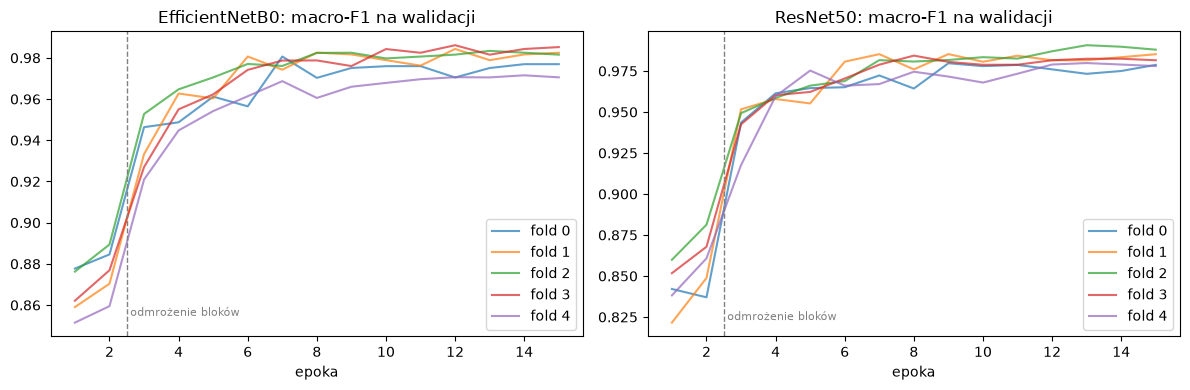

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ['efficientnet_b0', 'resnet50']):
    for f in cv[m]['folds']:
        h = pd.DataFrame(f['history'])
        ax.plot(h.epoch, h.val_macro_f1, alpha=0.7, label=f"fold {f['fold']}")
    ax.axvline(2.5, color='gray', ls='--', lw=1)
    ax.text(2.6, ax.get_ylim()[0] + 0.01, 'odmrożenie bloków', fontsize=8, color='gray')
    ax.set_title(f'{MODELS[m]}: macro-F1 na walidacji')
    ax.set_xlabel('epoka')
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'cv_transfer_krzywe.png', dpi=150)
plt.show()

## Porównanie trzech modeli (walidacja krzyżowa, 5 foldów)

In [3]:
rows = []
for m, name in MODELS.items():
    folds = pd.DataFrame([{k: v for k, v in f.items() if k != 'history'} for f in cv[m]['folds']])
    sec = np.mean([np.mean([h['seconds'] for h in f['history']]) for f in cv[m]['folds']])
    row = {'model': name, 'parametry [mln]': count_params(build_model(m)) / 1e6,
           's / epoka': sec, 'najlepsza epoka (mediana)': folds.best_epoch.median()}
    for c in ['accuracy', 'macro_f1', 'macro_recall', 'macro_specificity', 'macro_auc']:
        row[c] = f'{folds[c].mean():.4f} ± {folds[c].std():.4f}'
    rows.append(row)
comparison = pd.DataFrame(rows).round(2)
comparison.to_csv(METRICS_DIR / 'cv_porownanie.csv', index=False)
comparison

,model,parametry [mln],s / epoka,najlepsza epoka (mediana),accuracy,macro_f1,macro_recall,macro_specificity,macro_auc
0,CNN od zera,1.17,10.67,28.0,0.9555 ± 0.0059,0.9549 ± 0.0059,0.9550 ± 0.0058,0.9852 ± 0.0019,0.9945 ± 0.0015
1,EfficientNetB0,4.01,5.56,12.0,0.9815 ± 0.0057,0.9812 ± 0.0058,0.9814 ± 0.0057,0.9939 ± 0.0019,0.9988 ± 0.0005
2,ResNet50,23.52,10.60,9.0,0.9842 ± 0.0045,0.9840 ± 0.0045,0.9841 ± 0.0045,0.9948 ± 0.0015,0.9990 ± 0.0003


## Macierz pomyłek z predykcji out-of-fold
Każdy obraz treningowy był raz w foldzie walidacyjnym, więc z 5 foldów składamy predykcje
dla wszystkich 5500 obrazów (bez dotykania testu).

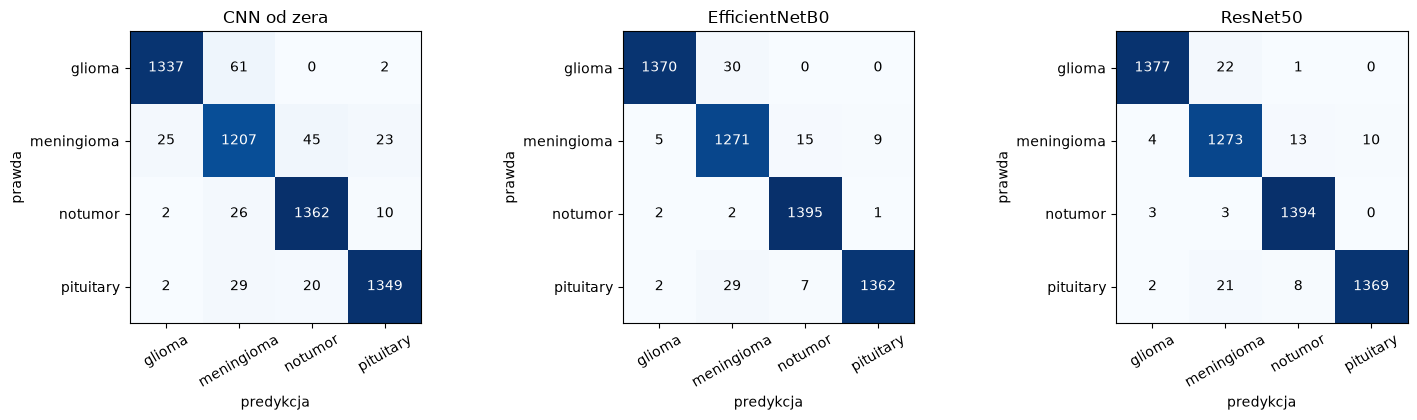

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, m in zip(axes, MODELS):
    oof = pd.read_csv(METRICS_DIR / f'oof_{m}.csv')
    pred = oof[[f'p_{c}' for c in CLASSES]].to_numpy().argmax(1)
    cm = confusion_matrix(oof.label, pred)
    ax.imshow(cm, cmap='Blues')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(4), CLASSES, rotation=30)
    ax.set_yticks(range(4), CLASSES)
    ax.set_xlabel('predykcja')
    ax.set_ylabel('prawda')
    ax.set_title(MODELS[m])
plt.tight_layout()
plt.savefig(FIG_DIR / 'cv_macierze_oof.png', dpi=150)
plt.show()

## Interpretacja
- Oba modele z transferem wiedzy są wyraźnie lepsze od CNN od zera (macro-F1 ok. 0,98 wobec 0,955)
  i uczą się dużo szybciej: duży skok następuje zaraz po odmrożeniu bloków (epoka 3), a od ok. 8 epoki
  krzywe są płaskie. Ostatnia epoka jest więc blisko najlepszej, co uzasadnia trenowanie modelu
  końcowego pełne 15 epok bez walidacji.
- ResNet50 ma najwyższe średnie macro-F1 (0,984 wobec 0,981 dla EfficientNetB0), ale różnica jest
  mniejsza niż odchylenie między foldami - modele są praktycznie równorzędne. EfficientNetB0 ma
  6 razy mniej parametrów i jest ok. 2 razy szybszy, co przy wdrożeniu byłoby jego zaletą.
- Zgodnie z przyjętą regułą (najwyższa średnia w CV) do strojenia w notatniku 04 wybieramy **ResNet50**.
- Macierze pomyłek out-of-fold: najczęstsze błędy to glejak -> oponiak oraz guz przysadki -> oponiak.
  Klasa `notumor` jest rozpoznawana niemal bezbłędnie. Biorąc pod uwagę, że obrazy `notumor`
  pochodzą z innych źródeł (inne rozmiary i sekwencje), łatwość tej klasy może wynikać po części
  z rozpoznawania źródła - sprawdzamy to w notatniku 05.